# Datos y muestra

Primera exploración del paper de liquidez bancaria y sustitución fintech.

Se auditan los 24 cortes de la muestra de personas y se contrasta su peso con el agregado completo. No se estima un efecto de las LEFI. Todas las salidas son agregadas; los identificadores permanecen dentro de DuckDB.

**Criterio de lectura:** fintech significa PNFC clasificado como fintech; no incluye automáticamente bancos digitales. El corte retrospectivo y la clasificación provisional limitan la interpretación de entradas, salidas y mora.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Permite ejecutar desde la raíz o desde cualquier subcarpeta del repositorio.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data/processed/ipc.dta').exists())
notebook_dir = root / 'Code/analysis/liquidez_fintech'
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
from common import (ROOT, DATA, CENDEU, HERE, OUT, BASELINE, GROUPS, COLORS,
                    connect, lender_taxonomy, price_index, figure_style,
                    time_axis, save_figure, record_inputs)
figure_style()
pd.set_option('display.max_rows', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
con = connect()
tax = lender_taxonomy()
con.register('tax', tax)

## Fuentes y fecha de referencia

Mayo de 2025 precede al anuncio de junio. Los archivos se leen tal como están: no se reconstruyen bases de otros agentes. `*_inputs.json` registra versiones de paquetes, rutas relativas, tamaño y fecha de modificación de los insumos.

In [2]:
parts = sorted((CENDEU / 'person_lender_5pct').glob('part-*.parquet'))
assert len(parts) == 24, 'Revisar cobertura: se esperan 24 archivos mensuales.'
inputs = parts + list((CENDEU/'lender_month').glob('*.parquet')) + [
    DATA/'balances_bancos.dta', DATA/'ipc.dta', ROOT/'Data/crosswalks/cendeu_lenders.csv']
record_inputs(inputs, '01')
ipc = price_index()
display(pd.DataFrame({'fuente':['Muestra de personas','IPC nacional'],
                      'cobertura':[f'{len(parts)} particiones; fechas auditadas abajo',
                                   f'{ipc.fecha.min():%m/%Y}–{ipc.fecha.max():%m/%Y}']}))

,fuente,cobertura
0,Muestra de personas,24 particiones; fechas auditadas abajo
1,IPC nacional,12/2016–06/2026


## Clasificación de acreedores

Se distingue régimen regulatorio y categoría digital. Las entidades de garantía no se suman al saldo crediticio principal. La vista analítica no corrige el archivo fuente: identifica bancos con IEF y deja marcadas las inconsistencias de categorías para su revisión histórica.

In [3]:
summary = tax.groupby('grupo', observed=True).agg(entidades=('ent','nunique')).reindex(GROUPS).fillna(0)
display(summary)
display(tax.loc[tax.revision.ne(''), ['ent','name','group','grupo','revision']].reset_index(drop=True))
tax[['ent','name','group','grupo','is_bank','is_fintech','include_credit','revision']].to_csv(
    OUT/'clasificacion_analitica.csv', index=False)

,entidades
grupo,
Bancos tradicionales,60
Bancos digitales,2
Financieras digitales,2
Fintech PNFC,7
Otros prestamistas,448
Garantías,58
Sin clasificar,10


,ent,name,group,grupo,revision
0,259,BANCO BMA S.A.U.,banco_privado_nacional,Bancos tradicionales,Banco fuera del corte IEF de mayo; fechar cont...
1,44077,COMPAÑIA FINANCIERA ARGENTINA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
2,44088,VOLKSWAGEN FINANCIAL SERVICES COMPAÑIA FINANCI...,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
3,44092,FCA COMPAÑIA FINANCIERA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
4,44093,GPAT COMPAÑIA FINANCIERA S.A.U.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
5,44094,MERCEDES-BENZ COMPAÑÍA FINANCIERA ARGENTINA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
6,44095,ROMBO COMPAÑÍA FINANCIERA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
7,44096,JOHN DEERE CREDIT COMPAÑÍA FINANCIERA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
8,44098,PSA FINANCE ARGENTINA COMPAÑÍA FINANCIERA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente
9,44099,TOYOTA COMPAÑÍA FINANCIERA DE ARGENTINA S.A.,fideicomiso,Otros prestamistas,Entidad regulada en IEF; revisar categoría fuente


## Integridad mensual

Se revisan claves deudor–acreedor, faltantes, montos negativos y consistencia de la muestra. El hash se contrasta con la versión actual de DuckDB; no se vuelve a sortear la muestra. Situación cero con saldo positivo queda como alerta, no se convierte en deuda sana.

In [4]:
audit_sql = (HERE/'sql/audit_month.sql').read_text()
audit_rows = []
for path in parts:
    row = con.execute(audit_sql, [str(path)]).fetchdf()
    row['archivo'] = path.name
    audit_rows.append(row)
audit = pd.concat(audit_rows, ignore_index=True)
audit['fecha'] = pd.to_datetime(dict(year=audit.year, month=audit.month, day=1))
audit = audit.sort_values('fecha').reset_index(drop=True)
assert audit.n_months.eq(1).all() and audit.fecha.is_unique
assert audit.fecha.tolist() == list(pd.date_range(audit.fecha.min(), audit.fecha.max(), freq='MS'))
assert audit[['duplicates','missing','negative']].eq(0).all().all(), 'Error de integridad; detener análisis.'
audit.to_csv(OUT/'auditoria_muestra_mensual.csv', index=False)
display(audit[['fecha','rows','borrowers_positive','lenders_positive','duplicates',
               'positive_status_zero','zero_with_status','unusual_status','outside_current_hash']])

,fecha,rows,borrowers_positive,lenders_positive,duplicates,positive_status_zero,zero_with_status,unusual_status,outside_current_hash
0,2024-08-01,1477268,866440,360,0,0,0,0,0
1,2024-09-01,1592306,882072,361,0,0,0,0,0
2,2024-10-01,1688253,898706,368,0,0,0,0,0
3,2024-11-01,1777923,912140,356,0,0,0,0,0
4,2024-12-01,1846432,920415,353,0,0,0,0,0
5,2025-01-01,1914368,931681,364,0,0,0,0,0
6,2025-02-01,1974121,938138,357,0,0,0,0,0
7,2025-03-01,2036191,947398,356,0,0,0,0,0
8,2025-04-01,2099267,960012,360,0,0,0,0,0
9,2025-05-01,2159537,970955,382,0,0,0,0,0


## ¿La muestra conserva una fracción razonable del universo?

`lender_month` agrega la población completa por acreedor. Se compara el saldo de la muestra con ese agregado, sin expandir montos por veinte. Los deudores únicos de la muestra no se suman entre acreedores.

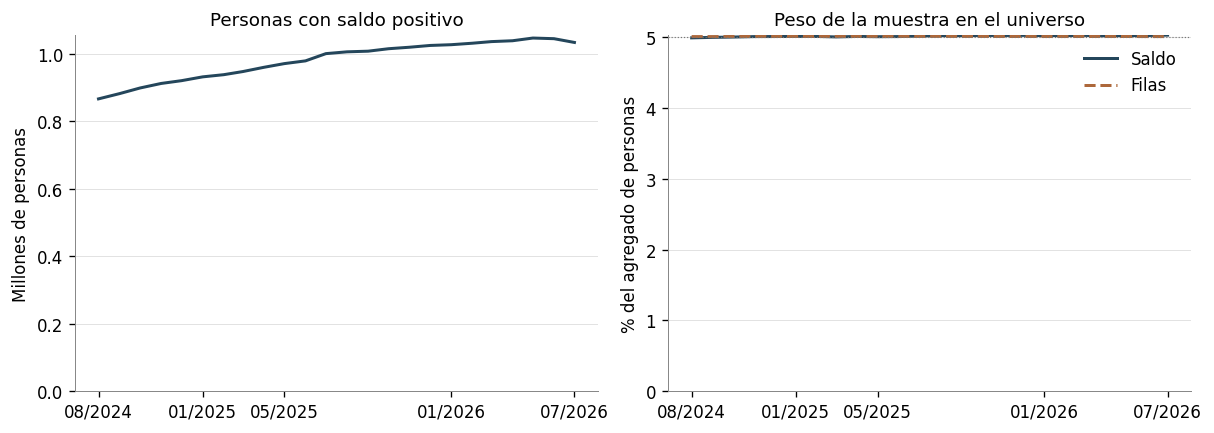

El saldo de la muestra representa entre **4.98% y 5.02%** del universo de personas. Esta comparación no certifica representatividad por riesgo, territorio o acreedor.

In [5]:
full = con.execute("""
    SELECT year, month, sum(credit_ars) AS full_amount,
           sum(relationships) AS full_rows
    FROM read_parquet(?) WHERE borrower_type='person'
    GROUP BY year, month
""", [str(CENDEU/'lender_month/*.parquet')]).fetchdf()
full['fecha'] = pd.to_datetime(dict(year=full.year,month=full.month,day=1))
coverage = audit.merge(full, on=['fecha','year','month'], validate='one_to_one')
assert len(coverage) == 24 and coverage.full_amount.gt(0).all()
coverage['share_amount'] = 100 * coverage.amount_ars / coverage.full_amount
coverage['share_rows'] = 100 * coverage.rows / coverage.full_rows
coverage.to_csv(OUT/'cobertura_muestra.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
axes[0].plot(coverage.fecha,coverage.borrowers_positive/1e6,color=COLORS['Bancos'])
axes[0].set(title='Personas con saldo positivo',ylabel='Millones de personas')
axes[0].set_ylim(bottom=0)
axes[1].plot(coverage.fecha,coverage.share_amount,label='Saldo',color=COLORS['Bancos'])
axes[1].plot(coverage.fecha,coverage.share_rows,label='Filas',color=COLORS['Fintech PNFC'],linestyle='--')
axes[1].axhline(5,color='#777777',linewidth=.7,linestyle=':')
axes[1].set(title='Peso de la muestra en el universo',ylabel='% del agregado de personas')
axes[1].set_ylim(bottom=0)
axes[1].legend()
for ax in axes: time_axis(ax,coverage.fecha)
save_figure(fig,'01_cobertura'); plt.show()
display(Markdown(f'El saldo de la muestra representa entre **{coverage.share_amount.min():.2f}% y {coverage.share_amount.max():.2f}%** del universo de personas. Esta comparación no certifica representatividad por riesgo, territorio o acreedor.'))

## Superposición en mayo de 2025

La unidad es la persona con saldo positivo. Se cuentan acreedores bancarios y presencia de al menos un PNFC fintech. No se exige que las relaciones sobrevivan después de mayo.

In [6]:
baseline_path = next(CENDEU/'person_lender_5pct'/name for name in audit.loc[audit.fecha.eq(BASELINE),'archivo'])
overlap = con.execute("""
    WITH people AS (
        SELECT p.cuit, count(DISTINCT p.ent) FILTER (WHERE t.is_bank) AS banks,
               bool_or(coalesce(t.is_fintech,false)) AS fintech
        FROM read_parquet(?) p LEFT JOIN tax t USING(ent)
        WHERE amount_ars>0 GROUP BY p.cuit
    )
    SELECT count(*) AS personas,
           count(*) FILTER (WHERE banks>=1) AS con_banco,
           count(*) FILTER (WHERE banks>=2) AS multibanco,
           count(*) FILTER (WHERE banks>=1 AND fintech) AS banco_y_fintech,
           count(*) FILTER (WHERE banks>=2 AND fintech) AS multibanco_y_fintech
    FROM people
""",[str(baseline_path)]).fetchdf()
display(overlap.T.rename(columns={0:'Personas, mayo 2025'}))
overlap.to_csv(OUT/'superposicion_mayo2025.csv',index=False)
classification_coverage = con.execute("""
    SELECT coalesce(t.grupo,'Sin correspondencia') AS grupo,
           count(*) AS relaciones, sum(p.amount_ars) AS saldo,
           count(DISTINCT p.ent) AS entidades
    FROM read_parquet(?) p LEFT JOIN tax t USING(ent)
    WHERE p.amount_ars>0 GROUP BY 1 ORDER BY saldo DESC
""",[str(baseline_path)]).fetchdf()
classification_coverage['porcentaje_saldo'] = 100*classification_coverage.saldo/classification_coverage.saldo.sum()
display(classification_coverage[['grupo','entidades','relaciones','porcentaje_saldo']])
classification_coverage.to_csv(OUT/'cobertura_clasificacion_mayo2025.csv',index=False)

,"Personas, mayo 2025"
personas,970955
con_banco,711225
multibanco,168005
banco_y_fintech,148506
multibanco_y_fintech,47245


,grupo,entidades,relaciones,porcentaje_saldo
0,Bancos tradicionales,51,915944,81.21
1,Otros prestamistas,303,493876,13.78
2,Fintech PNFC,7,271406,3.10
3,Financieras digitales,2,84810,1.39
4,Bancos digitales,2,18767,0.50
5,Garantías,8,2702,0.02
6,Sin clasificar,9,203,0.00


## Qué queda habilitado y qué falta

La exploración siguiente puede trabajar con cohortes bancarias fijas y saldos reportados, incluyendo quienes dejan de aparecer. No identifica todavía restricciones de oferta.

- Revisar fusiones, cambios de entidad, licencias y cesiones antes de estimar shocks.
- El corte retrospectivo puede omitir relaciones históricas; no interpretar ausencias como pagos.
- Los nuevos campos de liquidez del código de construcción pueden no estar todavía en el `.dta`; verificarlo sin reconstruir el trabajo de otro agente.
- El vínculo acreedor→CUIT→deudor requiere un crosswalk legal fechado. El mapa de billeteras/FCI no alcanza.
- El siguiente notebook utiliza exclusivamente los meses con IPC observado y separa expansión agregada de sustitución individual.

In [7]:
balance_columns = pd.read_stata(DATA/'balances_bancos.dta',convert_categoricals=False).columns
available = [x for x in ['lefi','leliq','liq_publica'] if x in balance_columns]
display(pd.DataFrame({'campo':['lefi','leliq','liq_publica'],
                      'presente_en_dta':[x in available for x in ['lefi','leliq','liq_publica']]}))
con.close()

,campo,presente_en_dta
0,lefi,False
1,leliq,False
2,liq_publica,False
